In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")

# Reproducibility
np.random.seed(42)


In [ ]:

# Production countries
producers = {
    "X": {
        "factories": 10000,
        "avg_wage": 600,
        "worker_safety": 6.5,
        "env_impact": 8.5,
        "capacity": 1000,
        "production": 800
    },

    "Y": {
        "factories": 6000,
        "avg_wage": 150,
        "worker_safety": 4.0,
        "env_impact": 7.5,
        "capacity": 800,
        "production": 600
    },

    "Z": {
        "factories": 4000,
        "avg_wage": 300,
        "worker_safety": 6.0,
        "env_impact": 6.5,
        "capacity": 600,
        "production": 400
    }
}

# Consumer markets
consumers = {
    "A": {
        "demand": 1100
    },

    "B": {
        "demand": 700
    }
}

# Add production and consumption rates
for country, attributes in producers.items():
    attributes["production_rate"] = (
        attributes["production"] / attributes["capacity"]
    )

for market, attributes in consumers.items():
    attributes["consumption_rate"] = attributes["demand"]

# Display node attributes
print("PRODUCTION COUNTRIES")
display(pd.DataFrame(producers).T)

print("\nCONSUMER MARKETS")
display(pd.DataFrame(consumers).T)

total_production = sum(
    p["production"] for p in producers.values()
)

total_demand = sum(
    c["demand"] for c in consumers.values()
)

print("\nTotal initial production:", total_production)
print("Total consumer demand:", total_demand)


PRODUCTION COUNTRIES


,factories,avg_wage,worker_safety,env_impact,capacity,production,production_rate
X,10000.0,600.0,6.5,8.5,1000.0,800.0,0.800000
Y,6000.0,150.0,4.0,7.5,800.0,600.0,0.750000
Z,4000.0,300.0,6.0,6.5,600.0,400.0,0.666667



CONSUMER MARKETS


,demand,consumption_rate
A,1100,1100
B,700,700



Total initial production: 1800
Total consumer demand: 1800


Notice above how the total units produced is equal to the total consumer demand.

In [ ]:

# Create directed graph
G = nx.DiGraph()

# Add production nodes
for country, attributes in producers.items():
    G.add_node(
        country,
        node_type="production",
        **attributes
    )

# Add consumption nodes
for market, attributes in consumers.items():
    G.add_node(
        market,
        node_type="consumption",
        **attributes
    )

# Calculate total demand
total_demand = sum(
    c["demand"] for c in consumers.values()
)

# Proportional allocation of exports
for producer, p_attributes in producers.items():

    for market, c_attributes in consumers.items():

        export_volume = (
            p_attributes["production"]
            * c_attributes["demand"]
            / total_demand
        )

        G.add_edge(
            producer,
            market,
            weight=export_volume
        )

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

print("\nExport volumes:")

for u, v, data in G.edges(data=True):
    print(f"{u} -> {v}: {data['weight']:.2f}")


Nodes: 5
Edges: 6

Export volumes:
X -> A: 488.89
X -> B: 311.11
Y -> A: 366.67
Y -> B: 233.33
Z -> A: 244.44
Z -> B: 155.56


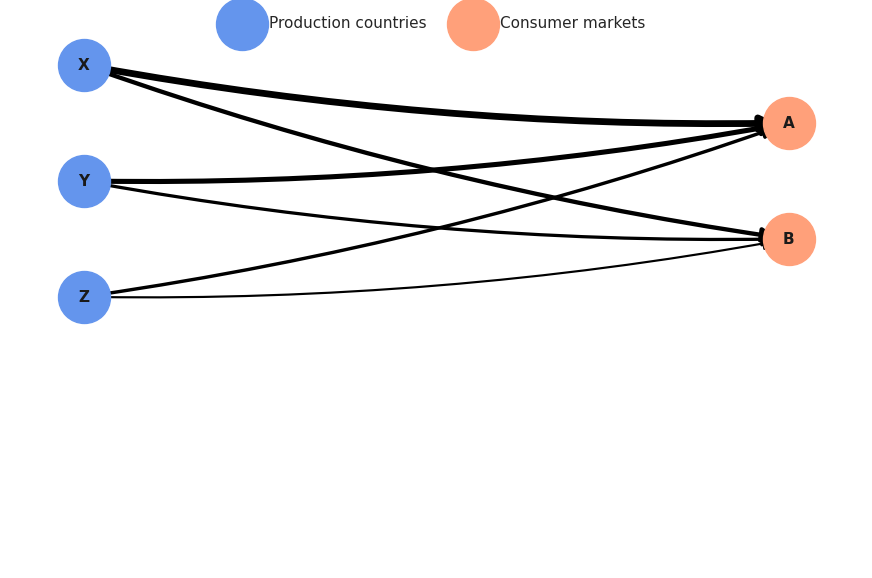

In [ ]:
#Visualizing the network

plt.figure(figsize=(11, 7))

# Position nodes in two columns
pos = {
    "X": (0, 2),
    "Y": (0, 1),
    "Z": (0, 0),
    "A": (3, 1.5),
    "B": (3, 0.5)
}

# Separate node types
production_nodes = [
    n for n, d in G.nodes(data=True)
    if d["node_type"] == "production"
]

consumer_nodes = [
    n for n, d in G.nodes(data=True)
    if d["node_type"] == "consumption"
]

# Draw production nodes
nx.draw_networkx_nodes(
    G, pos,
    nodelist=production_nodes,
    node_color="cornflowerblue",
    node_size=1400,
    label="Production countries"
)

# Draw consumer nodes
nx.draw_networkx_nodes(
    G, pos,
    nodelist=consumer_nodes,
    node_color="lightsalmon",
    node_size=1400,
    label="Consumer markets"
)

# Edge widths proportional to export volumes
edge_weights = [
    G[u][v]["weight"] for u, v in G.edges()
]

edge_widths = [
    w / 100 for w in edge_weights
]

nx.draw_networkx_edges(
    G, pos,
    width=edge_widths,
    edge_color="black",
    arrows=True,
    arrowsize=20,
    connectionstyle="arc3,rad=0.05"
)

nx.draw_networkx_labels(
    G, pos,
    font_size=11,
    font_weight="bold"
)






plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.05), ncol=2, frameon=False)
plt.axis("off")
plt.show()


In [ ]:
# Simulation 1: Removing the biggest hub

In [ ]:
# identifying the hub

# Calculate weighted out-degree for production nodes
production_centrality = {}

for node in production_nodes:

    production_centrality[node] = G.out_degree(
        node,
        weight="weight"
    )

print("Production node centrality (weighted out-strength):")

for country, centrality in production_centrality.items():
    print(f"{country}: {centrality:.2f}")

# Identify the largest production hub
target_hub = max(
    production_centrality,
    key=production_centrality.get
)

print("\nTargeted production hub:", target_hub)


Production node centrality (weighted out-strength):
X: 800.00
Y: 600.00
Z: 400.00

Targeted production hub: X


In [ ]:

def simulate_targeted_attack(attack_fraction):

    # Copy initial production values
    new_production = {
        country: attributes["production"]
        for country, attributes in producers.items()
    }

    # Identify targeted country
    original_target_production = (
        producers[target_hub]["production"]
    )

    # Calculate production removed
    production_removed = (
        original_target_production * attack_fraction
    )

    # Reduce production in targeted country
    new_production[target_hub] = (
        original_target_production - production_removed
    )

    # Identify other production countries
    other_producers = [
        country for country in producers
        if country != target_hub
    ]

    # Calculate spare capacity in other countries
    spare_capacity = {
        country: (
            producers[country]["capacity"]
            - producers[country]["production"]
        )
        for country in other_producers
    }

    total_spare_capacity = sum(spare_capacity.values())

    # Calculate how much production can be reallocated
    reallocated_production = min(
        production_removed,
        total_spare_capacity
    )

    # Allocate production proportionally to spare capacity
    for country in other_producers:

        if total_spare_capacity > 0:

            additional_production = (
                reallocated_production
                * spare_capacity[country]
                / total_spare_capacity
            )

        else:
            additional_production = 0

        new_production[country] += additional_production

    # Calculate total production after attack
    total_production = sum(new_production.values())

    # Calculate unmet consumer demand
    unmet_demand = total_demand - total_production

    # Return results
    return {
        "attack_fraction": attack_fraction,
        "production_removed": production_removed,
        "reallocated_production": reallocated_production,
        "total_production": total_production,
        "unmet_demand": max(0, unmet_demand),
        "production_by_country": new_production
    }


In [ ]:
# running simulation at different levels of intensity

# Define attack percentages
attack_levels = np.linspace(0, 1, 21)

# Store simulation results
simulation_results = []

for attack in attack_levels:

    result = simulate_targeted_attack(attack)

    simulation_results.append(result)

# Convert results into a DataFrame
results_df = pd.DataFrame([
    {
        "Production Removed (%)": r["attack_fraction"] * 100,
        "X Production": r["production_by_country"]["X"],
        "Y Production": r["production_by_country"]["Y"],
        "Z Production": r["production_by_country"]["Z"],
        "Total Production": r["total_production"],
        "Production Reallocated": r["reallocated_production"],
        "Unmet Demand": r["unmet_demand"]
    }
    for r in simulation_results
])

display(results_df.round(2))


,Production Removed (%),X Production,Y Production,Z Production,Total Production,Production Reallocated,Unmet Demand
0,0.0,800.0,600.0,400.0,1800.0,0.0,0.0
1,5.0,760.0,620.0,420.0,1800.0,40.0,0.0
2,10.0,720.0,640.0,440.0,1800.0,80.0,0.0
3,15.0,680.0,660.0,460.0,1800.0,120.0,0.0
4,20.0,640.0,680.0,480.0,1800.0,160.0,0.0
5,25.0,600.0,700.0,500.0,1800.0,200.0,0.0
6,30.0,560.0,720.0,520.0,1800.0,240.0,0.0
7,35.0,520.0,740.0,540.0,1800.0,280.0,0.0
8,40.0,480.0,760.0,560.0,1800.0,320.0,0.0
9,45.0,440.0,780.0,580.0,1800.0,360.0,0.0


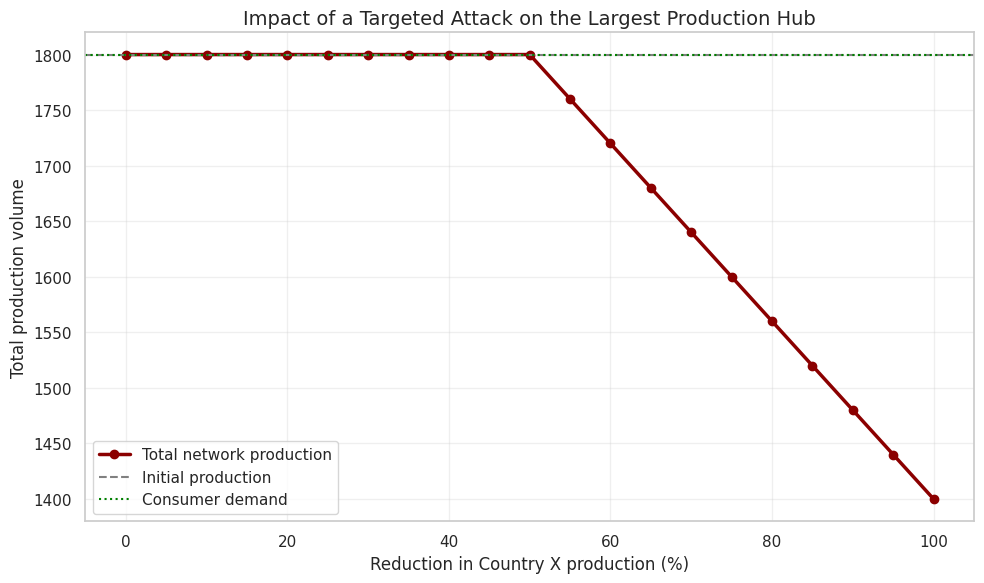

In [ ]:

plt.figure(figsize=(10, 6))

plt.plot(
    results_df["Production Removed (%)"],
    results_df["Total Production"],
    marker="o",
    linewidth=2.5,
    color="darkred",
    label="Total network production"
)

# Initial production reference
plt.axhline(
    y=total_production,
    color="gray",
    linestyle="--",
    label="Initial production"
)

# Total consumer demand
plt.axhline(
    y=total_demand,
    color="green",
    linestyle=":",
    label="Consumer demand"
)

plt.xlabel("Reduction in Country X production (%)", fontsize=12)
plt.ylabel("Total production volume", fontsize=12)

plt.title(
    "Impact of a Targeted Attack on the Largest Production Hub",
    fontsize=14
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


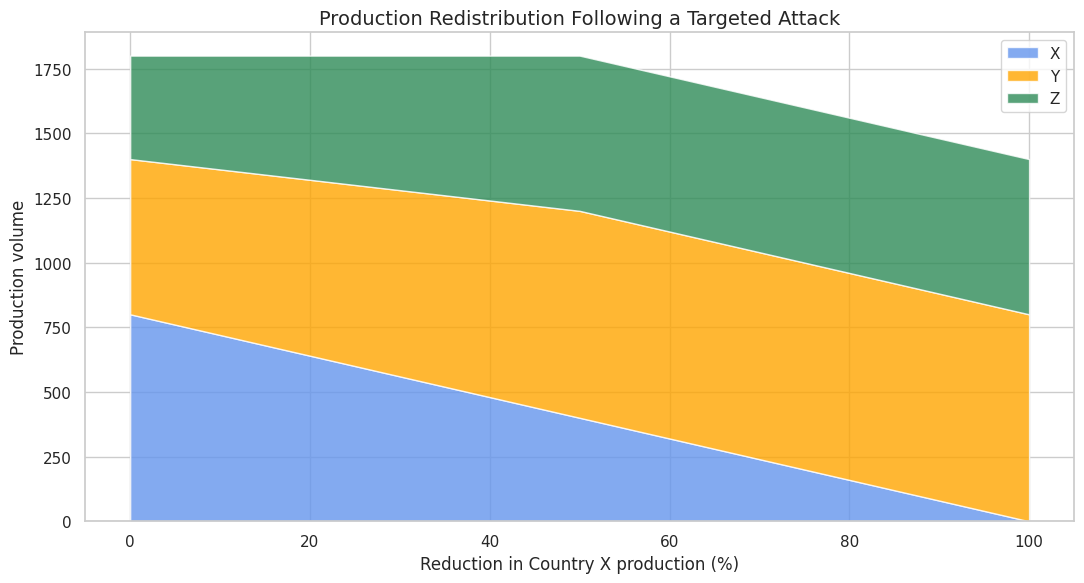

In [ ]:
# How does production get redistributed

plt.figure(figsize=(11, 6))

x = results_df["Production Removed (%)"]

plt.stackplot(
    x,
    results_df["X Production"],
    results_df["Y Production"],
    results_df["Z Production"],
    labels=["X", "Y", "Z"],
    colors=["cornflowerblue", "orange", "seagreen"],
    alpha=0.8
)

plt.xlabel("Reduction in Country X production (%)")
plt.ylabel("Production volume")

plt.title(
    "Production Redistribution Following a Targeted Attack",
    fontsize=14
)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


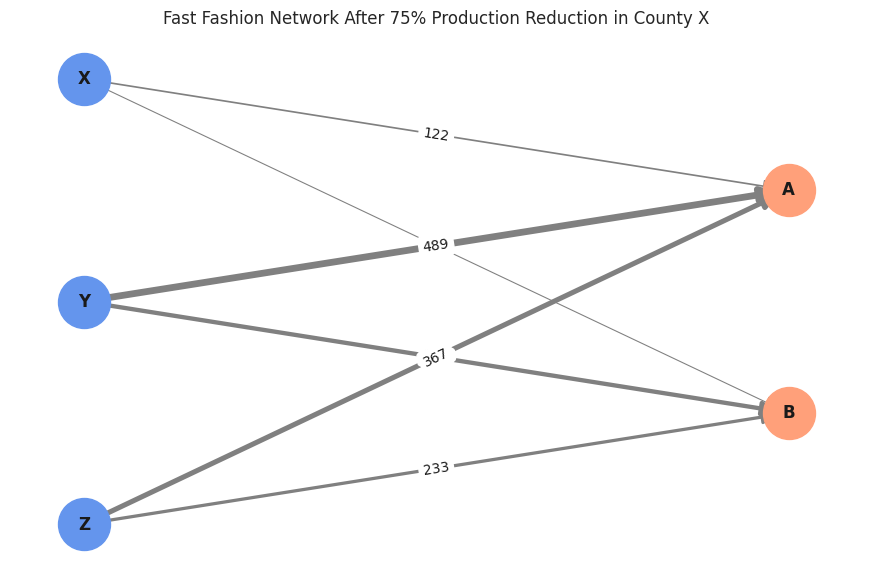

Production by country after attack:
X: 200.00
Y: 800.00
Z: 600.00

Total production: 1600.0
Unmet demand: 200.0


In [ ]:
# Visualizing the network after the disruption


# Simulate a 75% reduction in China
attack_result = simulate_targeted_attack(0.75)

# Create a copy of the original network
G_attack = G.copy()

# Update production node attributes
for country, production in attack_result["production_by_country"].items():

    G_attack.nodes[country]["production"] = production

    G_attack.nodes[country]["production_rate"] = (
        production / producers[country]["capacity"]
    )

# Update export volumes using proportional market allocation
for country in producers:

    for market in consumers:

        new_export = (
            attack_result["production_by_country"][country]
            * consumers[market]["demand"]
            / total_demand
        )

        G_attack[country][market]["weight"] = new_export

# Plot
plt.figure(figsize=(11, 7))

pos = {
    "X": (0, 2),
    "Y": (0, 1),
    "Z": (0, 0),
    "A": (3, 1.5),
    "B": (3, 0.5)
}

nx.draw_networkx_nodes(
    G_attack, pos,
    nodelist=production_nodes,
    node_color="cornflowerblue",
    node_size=1400
)

nx.draw_networkx_nodes(
    G_attack, pos,
    nodelist=consumer_nodes,
    node_color="lightsalmon",
    node_size=1400
)

weights = [
    G_attack[u][v]["weight"]
    for u, v in G_attack.edges()
]

nx.draw_networkx_edges(
    G_attack, pos,
    width=[w / 100 for w in weights],
    edge_color="gray",
    arrows=True,
    arrowsize=20
)

nx.draw_networkx_labels(
    G_attack, pos,
    font_weight="bold"
)

edge_labels = {
    (u, v): f"{d['weight']:.0f}"
    for u, v, d in G_attack.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G_attack, pos,
    edge_labels=edge_labels
)

plt.title("Fast Fashion Network After 75% Production Reduction in County X")

plt.axis("off")
plt.show()

print("Production by country after attack:")

for country, volume in attack_result["production_by_country"].items():
    print(f"{country}: {volume:.2f}")

print("\nTotal production:", attack_result["total_production"])
print("Unmet demand:", attack_result["unmet_demand"])
